# Intro
This Jupyter notebook is intended to be a reformatted version of code originally written by Dr. Leia Price.

### Required Packages

Matplotlib, NumPy, Pandas, and SciPy

### Purpose
This notebook will be used to find the Floquet exponents, $\gamma_k$ of particular solutions to the following differential equation known as Hill's equation:
$$
\ddot{X}+\left[A+2qP_{\mathrm{T}(t)} \right]X = 0
$$
Where $A$ and $q$ are free parameters and $P_\mathrm{T}(t)$ is some periodic function with period of $T$.

In particular, we are examining the Floquet exponents of the differential equation:
$$
X_k''+ \left[\frac{k^2}{\lambda\Phi^2}+\frac{g^2}{\lambda}\mathrm{cn}^2\left(\sqrt{\lambda}\Phi\eta,\frac{1}{2}\right)\right]X_k=0
$$
This differential equation can be found by solving for the equations of motions given a potential defined as:
$$
V(\phi,\chi)=\frac{\lambda}{4}\phi^4+\frac{1}{2}g^2\phi^2\chi^2
$$
(Omitting work involving rescalings, and approximations, and switching to Fourier space)

We can define $\kappa^2\equiv\frac{k^2}{\sqrt{\lambda}\Phi^2}$ and $q\equiv\frac{g^2}{\lambda}$,and $y=\sqrt{\lambda}\Phi\eta$, and our differential equation fits the Hill's equation form more nicely:

$$
X_k''+ \left[\kappa^2+q\cdot\mathrm{cn}^2\left(y,\frac{1}{2}\right)\right]X_k=0
$$

This differential equation is also known as Lame's equation!

In [1]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.special import ellipj,ellipk, ellipe
from numbalsoda import lsoda_sig, lsoda, dop853
from numba import njit, cfunc
import time

## Custom Functions

### Storing Data
The following function will be used later to store arrays containing 
- growth factor $\gamma_k$
- specific modes $k$
- ratio of $\frac{g^2}{\lambda}$, $q$

in a spreadsheet.


In [2]:
def save_xls(mydict, xls_path):
    with pd.ExcelWriter(xls_path) as writer:
        for n, df in mydict.items():
            pd.DataFrame(df).to_excel(writer, n, index=False)

### Elliptic Cosine
Rewritten from [Cephes Library](https://netlib.org/cephes/) into python (this will let us speed up find_mu), (look into multiprocessing?)

In [3]:
MACHEP = np.finfo(float).eps
@njit(cache=True, fastmath=True)
def ellpj(u,m):
    if m < 0 or m > 1:
        sn,cn,dn,ph = 0.0,0.0,0.0,0.0
        return sn,cn,dn,ph
    if m < 1.0e-9 :
        t = np.sin(u)
        b = np.cos(u)
        ai = 0.25*m*(u-t*b)
        sn = t-ai*b
        cn = b+ai*t
        dn = 1.0-0.5*m*t**2
        ph = u-ai
        return sn,cn,dn,ph
    if m >= 0.9999999999:
        ai =0.25 * (1-m)
        b = np.cosh(u)
        t = np.tanh(u)
        phi = 1.0/b
        twon = b * np.sinh(u)
        sn = t+ai*(twon-u)/(b**2)
        ph = 2.0*np.arctan(np.exp(u))-np.pi/2+ai*(twon-u)/b
        ai *= t * phi
        cn = phi - ai*(twon-u)
        dn = phi + ai * (twon+u)
        return sn,cn,dn,ph
     # A. G. M. scale
    a = np.zeros(9)
    c = np.zeros(9)

    a[0] = 1.0
    b = np.sqrt(1.0 - m)
    c[0] = np.sqrt(m)
    twon = 1.0
    i = 0

    while abs(c[i] / a[i]) > MACHEP:
        if i > 7:
            break
        ai = a[i]
        i += 1
        c[i] = (ai - b) / 2.0
        t = np.sqrt(ai * b)
        a[i] = (ai + b) / 2.0
        b = t
        twon *= 2.0

    # backward recurrence
    phi = twon * a[i] * u
    while True:
        t = c[i] * np.sin(phi) / a[i]
        b = phi
        phi = (np.arcsin(t) + phi) / 2.0
        i -= 1
        if i == 0:
            break

    t = np.sin(phi)
    sn = t
    cn = np.cos(phi)
    dn = np.sqrt(1.0 - m * t * t)
    ph = phi
    return sn,cn,dn,ph


### Lame Equation
The following helper function will be used in calculating the Floquet exponent and defines the periodic function that multiplies by $X_k$, $\kappa^2+q\cdot\mathrm{cn}^2(y,\frac{1}{2})$.


In [4]:
@cfunc(lsoda_sig)
def lame_rhs(t,x,dx,p):
    A = p[0]
    Q = p[1]
    sn,cn,dn,ph = ellpj(t,0.5)
    P= A + Q * cn * cn
    dx[0] = x[1]
    dx[1] = -P * x[0]
    
function_pointer = lame_rhs.address

### Floquet Exponent Finder
The following function uses `lame_eqn` in an initial value problem solver to then calculate the Floquet exponent. Note that it technically finds $\gamma_k\cdot T$ where $T$ is the length of one period of the elliptic cosine function $\mathrm{cn(y,\frac{1}{2})}$. We denote this difference as $\mu_k \equiv \gamma_k\cdot T$

In [5]:
Y = 4*ellipk(0.5) # period of elliptic cosine
print(Y)

def find_ck(A,Q,tmax):
    """
    Finds the growth rate, \gamma_k, multiplied by a period of the elliptic cosine with elliptic modulus 1/2, Y.
    parameters:
    A (\kappa^2) (float)
    q (g^2/\lambda) (float)
    """
    y0 = np.array([1.0,0.0])
    # t_span = np.array([0.0,tmax]) 
    t_span = np.linspace(0,tmax,num=1000)
    data=np.array([A,Q])
    soln, success = lsoda(function_pointer,y0,t_span,data=data,rtol=1e-10, atol=1e-12)
    # soln, success = lsoda(function_pointer,y0,t_span,data=data) 
    if not success:
        return 0 # TODO: figure out what to do when differential solver doesn't converge to a value.
    h = soln[-1,0]
    g = soln[-1,1]
    # h = soln[-1][0]
    # g = soln[-1][1]
    if A==0 and Q==0:
        B = np.identity(2)
    else:
        B = np.array( [ [h , (h / g ) *h - g**-1],[g,h]])
    return np.log(np.max(np.abs(np.linalg.eig(B)[0]))) 


7.4162987092054875


<>:5: SyntaxWarning: invalid escape sequence '\g'
<>:5: SyntaxWarning: invalid escape sequence '\g'
/var/folders/0t/tkrfdh952yq9xynmvfgqpwwc0000gn/T/ipykernel_30520/1094808076.py:5: SyntaxWarning: invalid escape sequence '\g'
  """


### Defining Parameters for single $q$ bands and finding $\mu_k$
From equation (52) in Greene et al. (1997), arXiv:hep-ph/9705347, in the limit of $q\gg 1$,
resonance is efficient when
$$
\kappa^2 \leq \sqrt{\frac{q}{2\pi^2}}
$$

At the moment (08/11/26) we will restrict our $A$ ($\kappa^2$) to be from $\left[0, 10\cdot\sqrt{\frac{q}{2\pi^2}}\right]$.

(10/29/26) Introducing range values relevant for in-between model which uses the same CMB-complying potential but non-minimal coupling values for $\lambda$.

In [6]:
# qs = [10**(7)]  # 10/22/26 - generating a q=10e7 single band sheet to vary g^2 and phi.

    
def generate_1d_qsheet(q_list,k_values,t_max,name):
    d = {}
    d.update({'qs':q_list})
    """
    generates a spreadsheet of the \gamma_k*Y and \kappa values for each value of q.
    Args:
        q_list (list): list of q values to solve lamé / mathieu equation for.
        k_values (list): which kappa values to calculate growth factor with.
        If no k_values list is provided, generate_q_sheet will generate a
        log-spaced range of k from 0 to \sqrt{\frac{q}{2pi^2}}.
        name (str): name of spreadsheet to save values to.
    """
    
    
    for q in q_list:
        ck = np.empty(len(k_values))
        for i, k_val in enumerate(k_values):
            start_time = time.perf_counter()
            ck[i] = find_ck(k_val,q,t_max)
            
            duration = time.perf_counter() - start_time
            print(f"entry {i} took {duration} seconds to evaluate!")
            # print(f'{i} /{len(ks)} complete')
        d[f'ck'] = ck
        d[f'ks'] = k_values
    save_xls(d,f'qsheets/{name}.xlsx')
    print(f'saved {name}!')
        

<>:7: SyntaxWarning: invalid escape sequence '\g'
<>:7: SyntaxWarning: invalid escape sequence '\g'
/var/folders/0t/tkrfdh952yq9xynmvfgqpwwc0000gn/T/ipykernel_30520/1665885258.py:7: SyntaxWarning: invalid escape sequence '\g'
  """


In [20]:
qs = [1000]
k_max = np.sqrt(qs[0]/(2*np.pi**2))
ks = np.logspace(0,k_max,num=2**10) # implied that each value in this array is actually kappa^2.
kappas_squared = ks**2 # need to square kappa because we solve using kappa_squared!
generate_1d_qsheet(qs,kappas_squared,Y, "NMC_qe3_log")

entry 0 took 0.005152208032086492 seconds to evaluate!
entry 1 took 0.0036270420532673597 seconds to evaluate!
entry 2 took 0.003692750004120171 seconds to evaluate!
entry 3 took 0.0033063330920413136 seconds to evaluate!
entry 4 took 0.003451791941188276 seconds to evaluate!
entry 5 took 0.0031192080350592732 seconds to evaluate!
entry 6 took 0.003138875006698072 seconds to evaluate!
entry 7 took 0.0033084580209106207 seconds to evaluate!
entry 8 took 0.0033043749863281846 seconds to evaluate!
entry 9 took 0.0034637920325621963 seconds to evaluate!
entry 10 took 0.0033578750444576144 seconds to evaluate!
entry 11 took 0.0034828749485313892 seconds to evaluate!
entry 12 took 0.0032314579002559185 seconds to evaluate!
entry 13 took 0.003212957992218435 seconds to evaluate!
entry 14 took 0.0033410839969292283 seconds to evaluate!
entry 15 took 0.003289083018898964 seconds to evaluate!
entry 16 took 0.003313792054541409 seconds to evaluate!
entry 17 took 0.003300915937870741 seconds to ev

[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000

entry 680 took 8.203884624992497 seconds to evaluate!
entry 681 took 0.007625917089171708 seconds to evaluate!
entry 682 took 0.007479915977455676 seconds to evaluate!
entry 683 took 0.00805099995341152 seconds to evaluate!
entry 684 took 0.008388124988414347 seconds to evaluate!
entry 685 took 0.007639708928763866 seconds to evaluate!


[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout


entry 686 took 9.068020457983948 seconds to evaluate!
entry 687 took 9.161534082959406 seconds to evaluate!
entry 688 took 9.37577191600576 seconds to evaluate!
entry 689 took 9.461159292026423 seconds to evaluate!
entry 690 took 9.646791959065013 seconds to evaluate!
entry 691 took 9.750946167041548 seconds to evaluate!
entry 692 took 9.919936749967746 seconds to evaluate!
entry 693 took 10.123123500030488 seconds to evaluate!
entry 694 took 10.29446383297909 seconds to evaluate!
entry 695 took 10.46146320796106 seconds to evaluate!


[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout


... (18 outputs left out)

entry 956 took 0.00996100006159395 seconds to evaluate!
entry 957 took 0.009724625037051737 seconds to evaluate!
entry 958 took 0.009850499918684363 seconds to evaluate!
entry 959 took 0.0102952909655869 seconds to evaluate!
entry 960 took 0.010662166983820498 seconds to evaluate!
entry 961 took 0.00985312508419156 seconds to evaluate!
entry 962 took 0.009801208972930908 seconds to evaluate!
entry 963 took 0.009788334020413458 seconds to evaluate!
entry 964 took 0.009812374948523939 seconds to evaluate!
entry 965 took 0.009710250073112547 seconds to evaluate!
entry 966 took 0.009764250018633902 seconds to evaluate!
entry 967 took 0.009714500047266483 seconds to evaluate!
entry 968 took 0.009967374964617193 seconds to evaluate!
entry 969 took 0.010052083991467953 seconds to evaluate!
entry 970 took 0.00977229094132781 seconds to evaluate!
entry 971 took 0.00972729199565947 seconds to evaluate!
entry 972 took 0.009834499913267791 seconds to evaluate!
entry 973 took 0.009745916933752596 s

[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000

entry 989 took 0.010125124943442643 seconds to evaluate!
entry 990 took 0.00980804197024554 seconds to evaluate!
entry 991 took 0.009822166990488768 seconds to evaluate!
entry 992 took 0.009705125004984438 seconds to evaluate!
entry 993 took 0.009758583037182689 seconds to evaluate!
entry 994 took 0.009779791929759085 seconds to evaluate!
entry 995 took 0.0102077079936862 seconds to evaluate!
entry 996 took 0.010248707956634462 seconds to evaluate!
entry 997 took 0.010010041994974017 seconds to evaluate!
entry 998 took 0.010027999989688396 seconds to evaluate!
entry 999 took 0.009717624983750284 seconds to evaluate!
entry 1000 took 0.009738833992742002 seconds to evaluate!
entry 1001 took 0.009729500045068562 seconds to evaluate!
entry 1002 took 0.009778916952200234 seconds to evaluate!
entry 1003 took 0.009732040925882757 seconds to evaluate!
entry 1004 took 0.009767582989297807 seconds to evaluate!
entry 1005 took 0.009708749945275486 seconds to evaluate!
entry 1006 took 0.0097484169

[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
[lsoda] 10000 steps taken before reaching tout
/var/folders/0t/tkrfdh952yq9xynmvfgqpwwc0000gn/T/ipykernel_30520/3758078560.py:4: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  pd.DataFrame(df).to_excel(writer, n, index=False)


## Defining Parameters for Floquet Maps

In [ ]:
def generate_2d_floquet_map(qs,ks,Y,q_sampling=100,kappa_sampling=100,file_name='2d_floquet_map'):
    """
    Generates a 2D floquet map of C_k (C_k = \gamma_k * Y).
    Args:
        qs (list): list of min and max value of q values to calculate C_k over.
        ks (list): list of min and max value of kappa values to calculate C_k over.
        Y (float): value of Hill's equation period. #TODO: fix what this actually means
        q_sampling (int, optional):. Defaults to 100.
        k_sampling (int, optional): _description_. Defaults to 100.
        file_name (str, optional): _description_. Defaults to '2d_floquet_map'.
    """
    
    q_range = np.logspace(qs[0],qs[1],num=q_sampling)
    k_range = np.logspace(ks[0],ks[1],num=kappa_sampling)
    ck_map = np.zeros(q_sampling,kappa_sampling)
    d = {}
    for i, q in enumerate(q_range):
        for j, k in enumerate(k_range):
            ck_map[i,j] = find_ck(k,q,Y)
    d.update({'qs':q_range,
              'ks':k_range,
              'cks':ck_map        
    })
    save_xls(d,f'{file_name}.xlsx')

computed 1 out of 40000 values: mu = 0.0
computed 2 out of 40000 values: mu = 0.0
computed 3 out of 40000 values: mu = 0.0
computed 4 out of 40000 values: mu = 0.0
computed 5 out of 40000 values: mu = 2.2204460492503128e-16
computed 6 out of 40000 values: mu = 0.0
computed 7 out of 40000 values: mu = -1.1102230246251565e-16
computed 8 out of 40000 values: mu = 0.0
computed 9 out of 40000 values: mu = -2.2204460492503136e-16
computed 10 out of 40000 values: mu = -1.1102230246251565e-16
computed 11 out of 40000 values: mu = 0.0
computed 12 out of 40000 values: mu = 0.0
computed 13 out of 40000 values: mu = -1.1102230246251565e-16
computed 14 out of 40000 values: mu = 0.0
computed 15 out of 40000 values: mu = 0.0
computed 16 out of 40000 values: mu = 0.0
computed 17 out of 40000 values: mu = 0.0
computed 18 out of 40000 values: mu = 0.0
computed 19 out of 40000 values: mu = 2.2204460492503128e-16
computed 20 out of 40000 values: mu = -1.1102230246251565e-16
computed 21 out of 40000 values

/var/folders/0t/tkrfdh952yq9xynmvfgqpwwc0000gn/T/ipykernel_42925/3758078560.py:4: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  pd.DataFrame(df).to_excel(writer, n, index=False)


In [ ]:
q = [1e1, 1e3]
ks = [2**(-3),2**4]
kappas_squared = ks**2
generate_2d_floquet_map(qs,kappas_squared,q_sampling=6,kappa_sampling=512,file_name='NMC_qsheets')

# Plots

In [21]:
# plot settings
plt.rcParams["font.family"] = "serif"
plt.rcParams["mathtext.fontset"] = "dejavuserif"
plt.rcParams['font.size'] = 18
plt.rcParams['lines.linewidth'] = 1.7
plt.rc('legend',fontsize=12, title_fontsize=14)
plt.rcParams['figure.figsize'] = (10, 7)  # default is (6.4, 4.8)

### Single $q$ band plotting

#### Plotting $\gamma_k$ vs $\kappa$ for given $q$

In [ ]:
plt.clf()
xlsx = 'numba_floquet_1997_recreation'
q_list= [5]# change this to get different gamma_k vs kappa at different q
for q_power in q_list: 
    gamma_k = np.squeeze(pd.read_excel(f'{xlsx}.xlsx',sheet_name=f'gs_{q_power}').values) / t_period
    kappas = np.squeeze(pd.read_excel(f'{xlsx}.xlsx',sheet_name=f'ks_{q_power}').values)

    plt.plot(kappas,gamma_k)
    plt.axvline(x=np.power(10**q_power/(2*(np.pi**2)),0.25),linestyle='--',color='red',label=r'efficient resonance limit, $\kappa^2 = \sqrt{\frac{q}{2\pi^2}}$, Greene et al.') # efficient resonance limit
    plt.xlabel(r'$\kappa$')
    plt.ylabel(r'$\gamma_k$')
    plt.title(rf'$q=10^{q_power}$')
    plt.legend()
    plt.savefig(f'{xlsx}-q=1e{q_power}-gamma-kappa.png')

#### Plotting $\frac{\gamma}{m_\mathrm{eff}}$ vs $\kappa$ for given $q$

In [ ]:
plt.clf()
xlsx = 'numba_floquet_1997_recreation'
def meff_squared(foo):
    return foo * cn_squared_avg # foo to represent an arbitrary constant
# q_power= 5# change this to get different gamma_k vs kappa at different q
q_list = [10**power for power in range(2,8)]
gamma_max_list = []
gamma_max_over_meff_chi_list = []
for q in q_list:
    gamma_k = np.squeeze(pd.read_excel(f'{xlsx}.xlsx',sheet_name=f'gs_{np.log10(q):.0f}').values) / t_period 
    gamma_max = np.max(gamma_k)
    gamma_max_list.append(gamma_max) # returns the max growth factor value for 
    gamma_max_over_meff_chi_list.append(gamma_max/np.sqrt(meff_squared(q)))
cn_squared_avg = ((0.5-1)*(ellipk(0.5))+ellipe(0.5))/(0.5*ellipk(0.5))

# m_eff_phi = np.sqrt(meff(3)) 
# m_eff_chi = np.sqrt(meff(q)) 
gamma_max_over_meff_phi_list = gamma_max_list/ np.sqrt(meff_squared(3))
gamma_max_over_H = np.array(gamma_max_list) * np.sqrt(1.5)
list_dict = {
'q':q_list,
'gamma_max':gamma_max_list,
'gamma_over_meff_phi':gamma_max_over_meff_phi_list,
'gamma_over_meff_chi':gamma_max_over_meff_chi_list,
'gamma_over_H':gamma_max_over_H
}
table = pd.DataFrame(list_dict)
print(table)

ValueError: Worksheet named 'gs_2' not found

### Floquet Maps
plotting 

0.23768476261689295


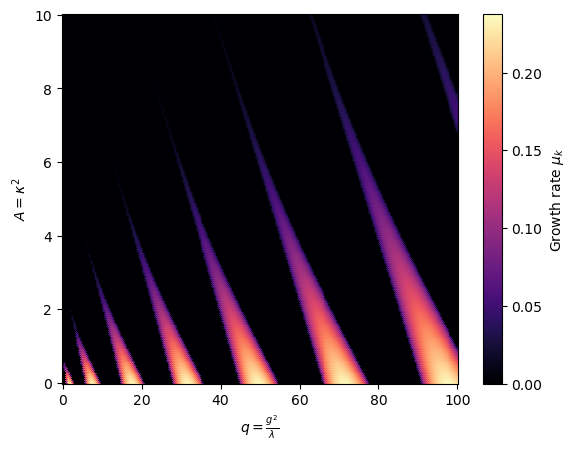

In [9]:
plt.clf()

mus = np.squeeze(pd.read_excel(file_name, sheet_name='gs').values)
As = np.squeeze(pd.read_excel(file_name, sheet_name='ks').values)
Qs = np.squeeze(pd.read_excel(file_name, sheet_name='qs').values)
plot = plt.pcolormesh(Qs, As, (mus.T/Y), cmap='magma', shading='auto', alpha=1)
# ctr = plt.contour(Qs,As,mus.T/tmax,5,colors='k')
print(np.max(mus/Y))
plot.set_edgecolor('face')
clb = plt.colorbar(plot,label=r'Growth rate $\mu_k$')
# sct = plt.scatter(3,1.6,color='green',marker='o')
plt.ylabel(r'$A=\kappa^2$')
plt.xlabel(r'$q=\frac{g^2}{\lambda}$')
plt.savefig('figure_01_floquet_map_recreation.png')
plt.show()
